In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from chemevo import evolution as evo

params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 14,
   'xtick.minor.visible': True,
   'ytick.minor.visible': True,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15,
   'xtick.direction': 'in',
   'ytick.direction': 'in',
   'xtick.top': True,
   'ytick.right': True,
   'xtick.major.size': 6,
   'xtick.minor.size': 3,
   'ytick.major.size': 6,
   'ytick.minor.size': 3
   }
rcParams.update(params)

sol_to_earth = 332946.078
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B",   # Muted Purple
    'black',
    'gray',
    'red',
    'blue',
    'green',
    'magenta'
]

In [2]:
cham_cont_as = np.loadtxt("/Users/honeyeah/Codes/data/cham_cont/cham_cont_47/cont_semis.txt")
cham_cont_ms = np.loadtxt("/Users/honeyeah/Codes/data/cham_cont/cham_cont_47/cont_masses.txt")

cham_cont_df = pd.DataFrame(columns=['m', 'a'])
cham_cont_df['m'] = cham_cont_ms * sol_to_earth
cham_cont_df['a'] = cham_cont_as

In [3]:
cham_bi_embs = np.loadtxt("/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_3/cham_bimodal_emb_samples_sep3.txt")
cham_bi_pls = np.loadtxt("/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_3/cham_bimodal_pl_samples_sep3.txt")
emb_masses = np.ones(14) * 2.8e-7 * sol_to_earth
pl_masses = np.ones(140) * 2.8e-8 * sol_to_earth

cham_semis = np.concatenate([cham_bi_embs, cham_bi_pls])
cham_masses = np.concatenate([emb_masses, pl_masses])

cham_bi_df = pd.DataFrame(columns=['m', 'a'])
cham_bi_df['a'] = cham_semis
cham_bi_df['m'] = cham_masses

In [4]:
ueda_semis = np.loadtxt("ueda_2021_v5.txt")
ueda_ms = np.ones(len(ueda_semis)) * 4.405e-8 * sol_to_earth
ueda_df = pd.DataFrame(columns=['m', 'a'])
ueda_df['m'] = ueda_ms
ueda_df['a'] = ueda_semis

In [5]:
def get_f(x, cmf_in, cmf_tot):
    f = x/(cmf_in/cmf_tot + x - 1)
    return f

def get_mass_inner(masses, semis, bound):
    m_in = 0
    for i in range(len(semis)):
        if semis[i] <= bound:
            m_in += masses[i]

    return m_in

def get_tot_mass(masses):
    return sum(masses)

def get_cmf_inner(cmf_tot, x, m_in, m_tot):
    return cmf_tot*((1-x) + x*(m_tot/m_in))

In [6]:
cham_cont_mtot = get_tot_mass(cham_cont_df['m'])
cham_bi_mtot = get_tot_mass(cham_bi_df['m'])
ueda_mtot = get_tot_mass(ueda_df['m'])

print("for Chambers bimodal M_tot (M_Earth) = ", get_tot_mass(cham_bi_df['m']))
print("for Chambers cont M_tot (M_Earth) = ", get_tot_mass(cham_cont_df['m']))
print("for Ueda v5 M_tot (M_Earth) = ", get_tot_mass(ueda_df['m']))

for Chambers bimodal M_tot (M_Earth) =  2.6102972515199996
for Chambers cont M_tot (M_Earth) =  2.5357954471886046
for Ueda v5 M_tot (M_Earth) =  2.199941210385


In [7]:
bounds = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8]
#bounds = np.linspace(0.35, 0.8, 15)
percs = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]

cham_cont_m_ins = []
cham_bi_m_ins = []
ueda_m_ins = []
for i in range(len(bounds)):
    cham_cont_m_ins.append(get_mass_inner(cham_cont_df['m'], cham_cont_df['a'], bounds[i]))
    cham_bi_m_ins.append(get_mass_inner(cham_bi_df['m'], cham_bi_df['a'], bounds[i]))
    ueda_m_ins.append(get_mass_inner(ueda_df['m'], ueda_df['a'], bounds[i]))
cham_cont_m_ins = np.array(cham_cont_m_ins)
cham_bi_m_ins = np.array(cham_bi_m_ins)
ueda_m_ins = np.array(ueda_m_ins)

cham_cont_fs = cham_cont_m_ins/cham_cont_mtot
cham_bi_fs = cham_bi_m_ins/cham_bi_mtot
ueda_fs = ueda_m_ins/ueda_mtot

Text(0.5, 0.98, 'Fraction of mass in the inner disk needed, to make a 0.7 CMF in the inner disk, given x')

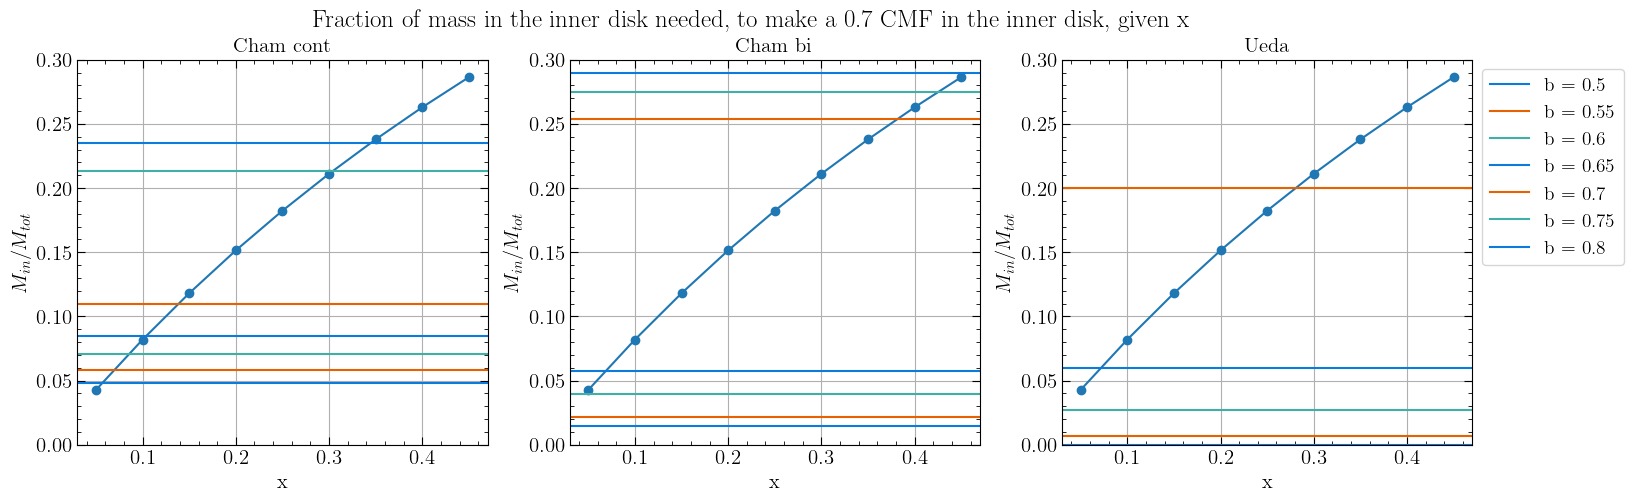

In [8]:
plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
plt.plot(percs, get_f(np.array(percs), 0.7, 0.33), marker='o')
for i in range(len(cham_cont_m_ins)):
    frac_cont = cham_cont_m_ins[i]/cham_cont_mtot
    plt.axhline(frac_cont, color = colors[np.mod(i,3)], linestyle = '-', label = f'Cham cont, b = {bounds[i]}')

plt.ylim(0, 0.3)
plt.title('Cham cont')
plt.grid('True')
plt.xlabel('x')
plt.ylabel(r'$M_{in}/M_{tot}$')


plt.subplot(1,3,2)
plt.plot(percs, get_f(np.array(percs), 0.7, 0.33), marker='o')
for i in range(len(cham_cont_m_ins)):
    frac_bi = cham_bi_m_ins[i]/cham_bi_mtot
    plt.axhline(frac_bi, color = colors[np.mod(i,3)], linestyle = '-', label = f'b = {bounds[i]}')

plt.ylim(0, 0.3)
plt.title('Cham bi')
#plt.legend(bbox_to_anchor = [1,1])
plt.grid('True')
plt.xlabel('x')
plt.ylabel(r'$M_{in}/M_{tot}$')

plt.subplot(1,3,3)
plt.plot(percs, get_f(np.array(percs), 0.7, 0.33), marker='o')
for i in range(len(ueda_m_ins)):
    frac_ueda = ueda_m_ins[i]/ueda_mtot
    plt.axhline(frac_ueda, color = colors[np.mod(i,3)], linestyle = '-', label = f'b = {bounds[i]}')

plt.ylim(0, 0.3)
plt.title('Ueda')
plt.legend(bbox_to_anchor = [1,1])
plt.grid('True')
plt.xlabel('x')
plt.ylabel(r'$M_{in}/M_{tot}$')

plt.suptitle('Fraction of mass in the inner disk needed, to make a 0.7 CMF in the inner disk, given x')

Text(0, 0.5, '$M_{in}/M_{tot}$')

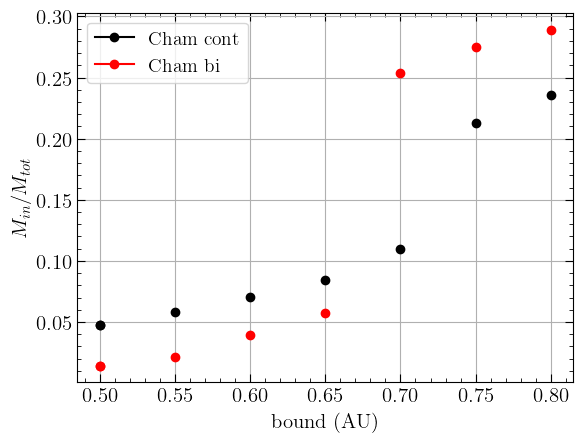

In [9]:
for i in range(len(cham_cont_m_ins)):
    frac_cont = cham_cont_m_ins[i]/cham_cont_mtot
    frac_bi = cham_bi_m_ins[i]/cham_bi_mtot
    if i == 0:
        plt.plot(bounds[i], frac_cont, color = 'black', label = f'Cham cont', marker = 'o')
        plt.plot(bounds[i], frac_bi, color = 'red', label = f'Cham bi', marker='o')
    plt.plot(bounds[i], frac_cont, color = 'black', marker = 'o')
    plt.plot(bounds[i], frac_bi, color = 'red', marker='o')

plt.legend()
plt.grid('True')
plt.xlabel('bound (AU)')
plt.ylabel('M_in/M_tot')
plt.ylabel(r'$M_{in}/M_{tot}$')

In [10]:
chamcont_cmf_ins = get_cmf_inner(0.33, np.array(percs), cham_cont_m_ins[0], cham_cont_mtot)
chambi_cmf_ins = get_cmf_inner(0.33, np.array(percs), cham_bi_m_ins[0], cham_bi_mtot)

In [11]:
chambi_cmf_ins[4]

np.float64(6.0225)

In [12]:
type(chambi_cmf_ins[0])

numpy.float64

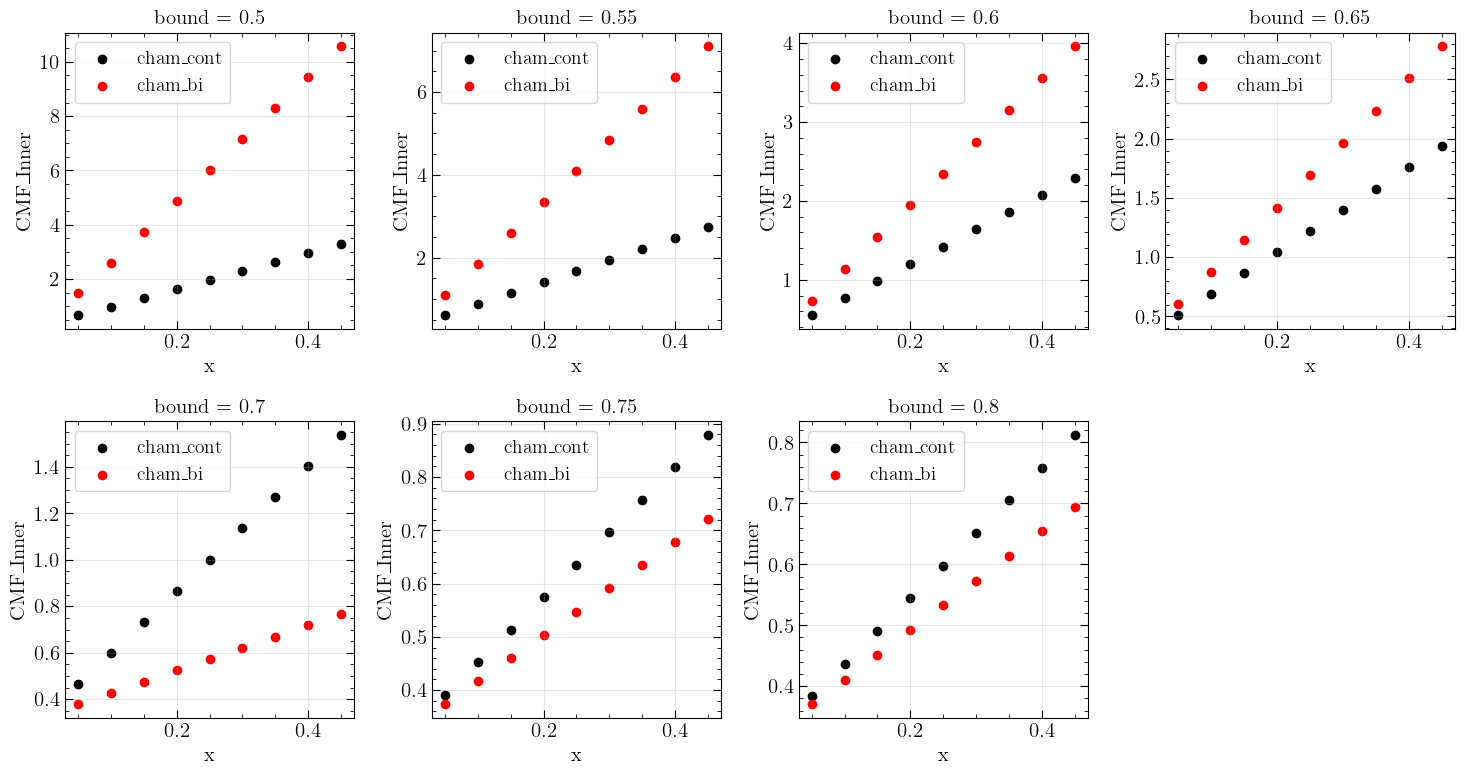

In [13]:
plt.figure(figsize=(15,8))

for i in range(len(bounds)):
    chamcont_cmf_ins = get_cmf_inner(0.33, np.array(percs), cham_cont_m_ins[i], cham_cont_mtot)
    chambi_cmf_ins = get_cmf_inner(0.33, np.array(percs), cham_bi_m_ins[i], cham_bi_mtot)
    plt.subplot(2,4,i+1)
    plt.scatter(percs, chamcont_cmf_ins, label = 'cham_cont', color = 'black')
    plt.scatter(percs, chambi_cmf_ins, label = 'cham_bi', color = 'red')
    plt.legend()
    plt.xlabel('x')
    plt.ylabel('CMF_Inner')
    plt.grid('True', alpha = 0.3)
    plt.title(f"bound = {bounds[i]}")

plt.tight_layout()

In [14]:
# -------------------------------------------------------------
# Constants (only used for plotting surface density)
# -------------------------------------------------------------
from astropy import units as u
Sigma1 = 8.0 # g/cm^2 at 1 AU
AU_cm = (1 * u.AU).to(u.cm).value
def compute_surface_density(semi_major_axes, masses, bins=None):
    """
    Estimate Sigma(a) from sampled bodies with individual masses.

    Parameters
    ----------
    semi_major_axes : array-like
        Semi-major axes of bodies (in AU).
    masses : array-like
        Corresponding masses of bodies (in grams).
    bins : array-like, optional
        Bin edges for semi-major axes (in AU). Default: np.linspace(0.3, 2.0, 25)

    Returns
    -------
    centers : np.ndarray
        Bin centers (AU).
    sigma : np.ndarray
        Surface density in g/cm^2 for each bin.
    """
    if bins is None:
        bins = np.linspace(0.3, 2.0, 20)
        
    masses = masses * u.M_earth.to(u.g)
    # total mass per bin
    mass_sum, edges = np.histogram(semi_major_axes, bins=bins, weights=masses)

    # area of each annulus (in cm^2)
    r1, r2 = edges[:-1], edges[1:]
    areas = np.pi * ((r2**2 - r1**2)) * AU_cm**2

    # surface density (mass per area)
    sigma = mass_sum / areas

    # bin centers
    centers = 0.5 * (r1 + r2)

    return centers, sigma

cents_cont, sigma_cont = compute_surface_density(cham_cont_df['a'], cham_cont_df['m'])
cents_bi, sigma_bi = compute_surface_density(cham_bi_df['a'], cham_bi_df['m'])

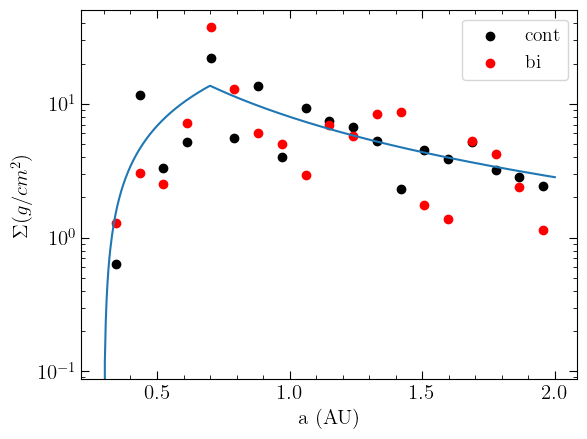

In [15]:
A_BREAK = 0.7
A_INNER_MIN = 0.3
def sigma_out(a):
    """Outer region surface density (a in AU): Sigma = 8 * a^(-3/2) g/cm^2."""
    return Sigma1 * a ** (-1.5)

def sigma_inner(a):
    """Linear taper from 0 at 0.3 AU to Sigma_out(0.7) at 0.7 AU."""
    Sbreak = sigma_out(A_BREAK)
    return Sbreak * (a - A_INNER_MIN) / (A_BREAK - A_INNER_MIN)

a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))
plt.plot(a, Sig)
plt.scatter(cents_cont, sigma_cont, label = 'cont', color ='black')
plt.scatter(cents_bi, sigma_bi, label = 'bi', color = 'red')
plt.xlabel('a (AU)')
plt.ylabel(r'$\Sigma (g/cm^2)$')
plt.legend()
plt.yscale('log')

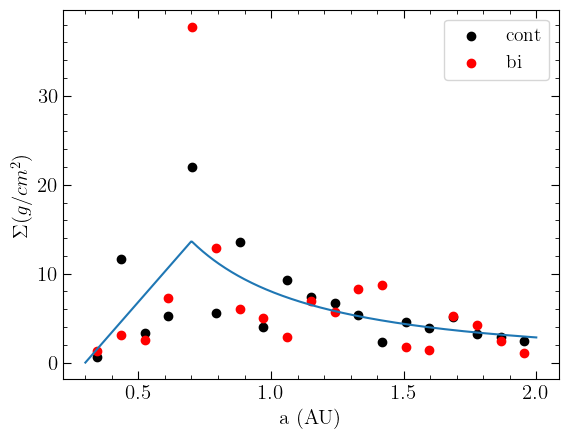

In [16]:
A_BREAK = 0.7
A_INNER_MIN = 0.3
def sigma_out(a):
    """Outer region surface density (a in AU): Sigma = 8 * a^(-3/2) g/cm^2."""
    return Sigma1 * a ** (-1.5)

def sigma_inner(a):
    """Linear taper from 0 at 0.3 AU to Sigma_out(0.7) at 0.7 AU."""
    Sbreak = sigma_out(A_BREAK)
    return Sbreak * (a - A_INNER_MIN) / (A_BREAK - A_INNER_MIN)

a = np.linspace(0.3, 2.0, 500)
Sig = np.where(a < A_BREAK, sigma_inner(a), sigma_out(a))
plt.plot(a, Sig)
plt.scatter(cents_cont, sigma_cont, label = 'cont', color ='black')
plt.scatter(cents_bi, sigma_bi, label = 'bi', color = 'red')
plt.xlabel('a (AU)')
plt.ylabel(r'$\Sigma (g/cm^2)$')
plt.legend()
#plt.yscale('log')

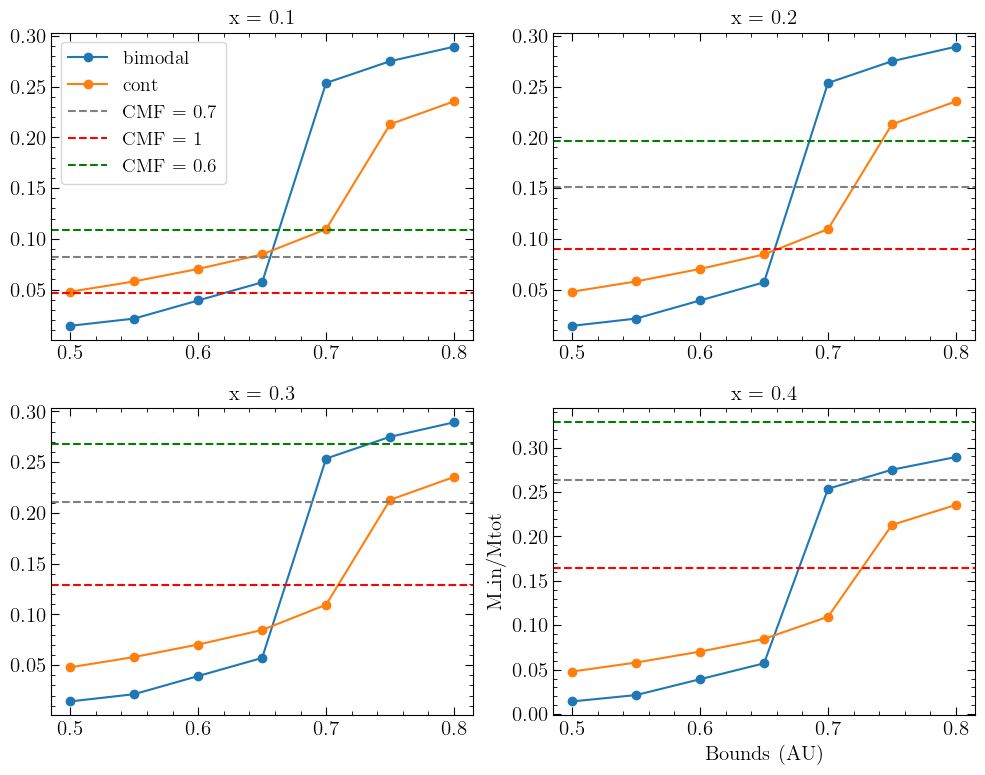

In [17]:
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.axhline(get_f(0.1, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'CMF = 0.7')
plt.axhline(get_f(0.1, 1, 0.33), color = 'red', linestyle = '--', label = 'CMF = 1')
plt.axhline(get_f(0.1, 0.6, 0.33), color = 'green', linestyle = '--', label = 'CMF = 0.6')
plt.title('x = 0.1')
plt.legend()

plt.subplot(2,2,2)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.axhline(get_f(0.2, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'x = 0.2, CMF = 0.7')
plt.axhline(get_f(0.2, 1, 0.33), color = 'red', linestyle = '--', label = 'x = 0.2, CMF = 1')
plt.axhline(get_f(0.2, 0.6, 0.33), color = 'green', linestyle = '--', label = 'x = 0.2, CMF = 0.6')
plt.title('x = 0.2')

plt.subplot(2,2,3)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.axhline(get_f(0.3, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'x = 0.3, CMF = 0.7')
plt.axhline(get_f(0.3, 1, 0.33), color = 'red', linestyle = '--', label = 'x = 0.3, CMF = 1')
plt.axhline(get_f(0.3, 0.6, 0.33), color = 'green', linestyle = '--', label = 'x = 0.3, CMF = 0.6')
plt.title('x = 0.3')

plt.subplot(2,2,4)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.axhline(get_f(0.4, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'x = 0.4, CMF = 0.7')
plt.axhline(get_f(0.4, 1, 0.33), color = 'red', linestyle = '--', label = 'x = 0.4, CMF = 1')
plt.axhline(get_f(0.4, 0.6, 0.33), color = 'green', linestyle = '--', label = 'x = 0.4, CMF = 0.6')
plt.title('x = 0.4')

plt.xlabel('Bounds (AU)')
plt.ylabel("M_in/Mtot")
#plt.legend(bbox_to_anchor = [1,1])
plt.tight_layout()

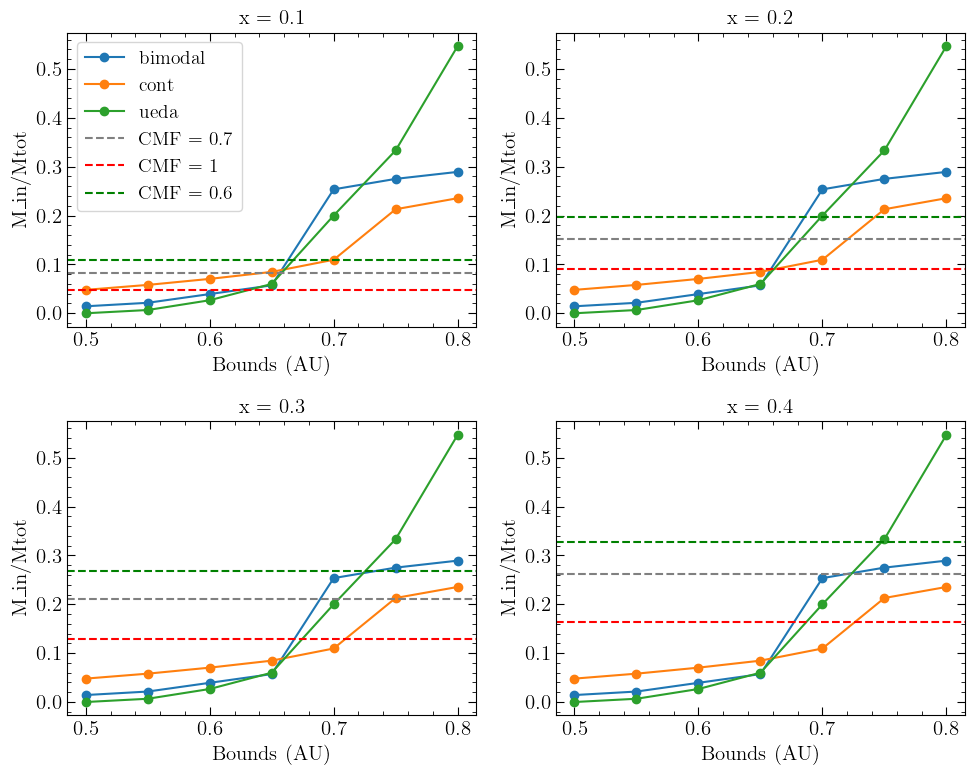

In [18]:
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.plot(bounds, ueda_fs, label = 'ueda', marker='o')
plt.axhline(get_f(0.1, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'CMF = 0.7')
plt.axhline(get_f(0.1, 1, 0.33), color = 'red', linestyle = '--', label = 'CMF = 1')
plt.axhline(get_f(0.1, 0.6, 0.33), color = 'green', linestyle = '--', label = 'CMF = 0.6')
plt.title('x = 0.1')
plt.ylabel("M_in/Mtot")
plt.xlabel('Bounds (AU)')
plt.legend()

plt.subplot(2,2,2)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.plot(bounds, ueda_fs, label = 'ueda', marker='o')
plt.axhline(get_f(0.2, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'x = 0.2, CMF = 0.7')
plt.axhline(get_f(0.2, 1, 0.33), color = 'red', linestyle = '--', label = 'x = 0.2, CMF = 1')
plt.axhline(get_f(0.2, 0.6, 0.33), color = 'green', linestyle = '--', label = 'x = 0.2, CMF = 0.6')
plt.title('x = 0.2')
plt.ylabel("M_in/Mtot")
plt.xlabel('Bounds (AU)')

plt.subplot(2,2,3)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.plot(bounds, ueda_fs, label = 'ueda', marker='o')
plt.axhline(get_f(0.3, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'x = 0.3, CMF = 0.7')
plt.axhline(get_f(0.3, 1, 0.33), color = 'red', linestyle = '--', label = 'x = 0.3, CMF = 1')
plt.axhline(get_f(0.3, 0.6, 0.33), color = 'green', linestyle = '--', label = 'x = 0.3, CMF = 0.6')
plt.title('x = 0.3')
plt.ylabel("M_in/Mtot")
plt.xlabel('Bounds (AU)')

plt.subplot(2,2,4)
plt.plot(bounds, cham_bi_fs, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_fs, label = 'cont', marker='o')
plt.plot(bounds, ueda_fs, label = 'ueda', marker='o')
plt.axhline(get_f(0.4, 0.7, 0.33), color = 'gray', linestyle = '--', label = 'x = 0.4, CMF = 0.7')
plt.axhline(get_f(0.4, 1, 0.33), color = 'red', linestyle = '--', label = 'x = 0.4, CMF = 1')
plt.axhline(get_f(0.4, 0.6, 0.33), color = 'green', linestyle = '--', label = 'x = 0.4, CMF = 0.6')
plt.title('x = 0.4')

plt.ylabel("M_in/Mtot")
plt.xlabel('Bounds (AU)')
#plt.legend(bbox_to_anchor = [1,1])
plt.tight_layout()

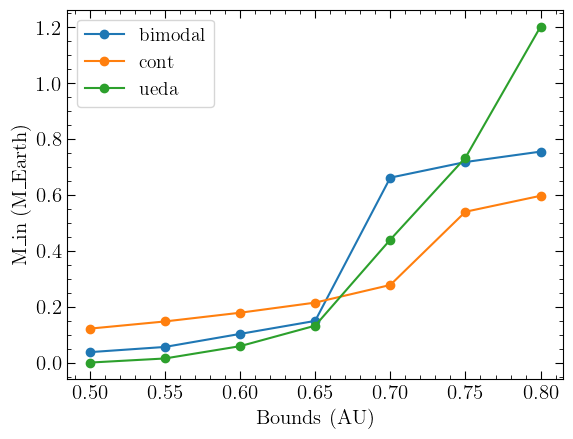

In [19]:
plt.plot(bounds, cham_bi_m_ins, label = 'bimodal', marker='o')
plt.plot(bounds, cham_cont_m_ins, label = 'cont', marker='o')
plt.plot(bounds, ueda_m_ins, label = 'ueda', marker='o')
#plt.axhline(get_f(0.1, 0.7, 0.33) * 2, color = 'gray', linestyle = '--', label = 'CMF = 0.7')
#plt.axhline(get_f(0.1, 1, 0.33) * 2, color = 'red', linestyle = '--', label = 'CMF = 1')
#plt.axhline(get_f(0.1, 0.6, 0.33) * 2, color = 'green', linestyle = '--', label = 'CMF = 0.6')
plt.ylabel("M_in (M_Earth)")
plt.xlabel('Bounds (AU)')
plt.legend()

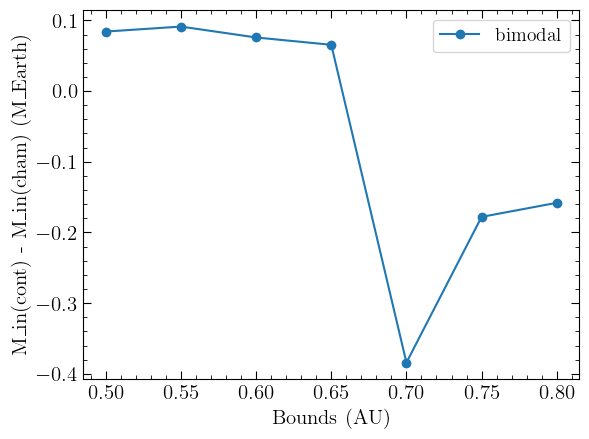

In [20]:
plt.plot(bounds, cham_cont_m_ins - cham_bi_m_ins, label = 'bimodal', marker='o')
#plt.plot(bounds, cham_cont_m_ins, label = 'cont', marker='o')

plt.ylabel("M_in(cont) - M_in(cham) (M_Earth)")
plt.xlabel('Bounds (AU)')
plt.legend()

# Binned masses

In [21]:
a_bins = np.linspace(0.3, 1, 15)
a_cent = np.zeros(len(a_bins) - 1)
m_binned_bi = np.zeros(len(a_bins) - 1)
m_binned_cont = np.zeros(len(a_bins) - 1)
for i in range(len(a_bins) - 1):
    m_binned_bi[i] = sum(cham_bi_df[(cham_bi_df['a'] < a_bins[i+1]) & (cham_bi_df['a'] > a_bins[i])]['m'])
    m_binned_cont[i] = sum(cham_cont_df[(cham_cont_df['a'] < a_bins[i+1]) & (cham_cont_df['a'] > a_bins[i])]['m'])
    a_cent[i] = (a_bins[i+1] + a_bins[i])/2

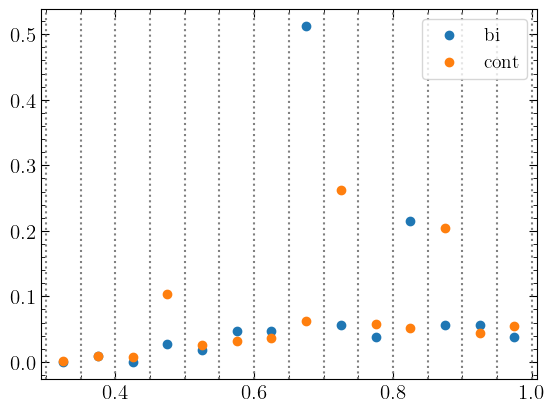

In [22]:
plt.scatter(a_cent, m_binned_bi, label = 'bi')
plt.scatter(a_cent, m_binned_cont, label = 'cont')
for i in range(len(a_bins)):
    plt.axvline(a_bins[i], linestyle=':', color = 'gray')

plt.legend()

In [23]:
cham_bi_cmf_grid = pd.read_csv("/Users/honeyeah/Codes/coregiver/examples/cham_bi_tajer/cham_bi_tajer_cmf_grid.csv")
cham_cont_cmf_grid = pd.read_csv("/Users/honeyeah/Codes/coregiver/examples/cham_cont/cham_cont_cmf_grid.csv")
ueda_cmf_grid = pd.read_csv("/Users/honeyeah/Codes/coregiver/examples/ueda_v5/ueda_v5_cmf_grid.csv")

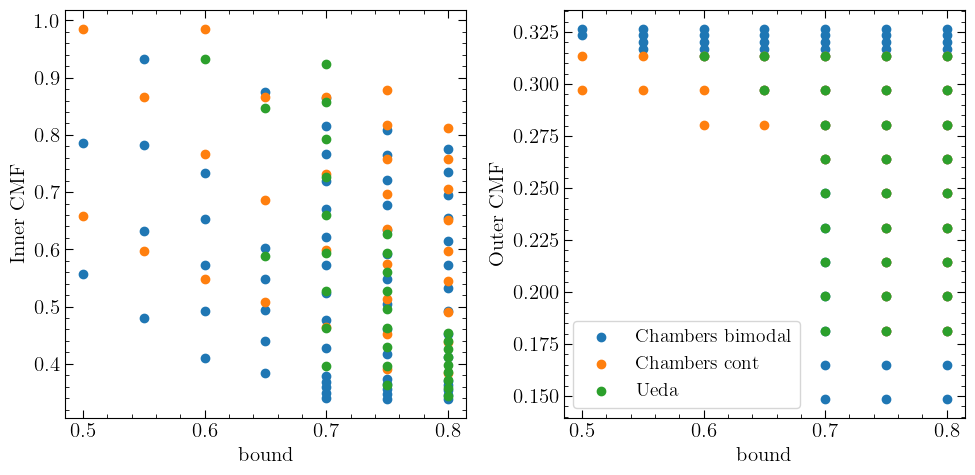

In [24]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)

plt.scatter(cham_bi_cmf_grid['bounds'], cham_bi_cmf_grid['inner_cmf'], label = 'Chambers bimodal')
plt.scatter(cham_cont_cmf_grid['bounds'], cham_cont_cmf_grid['inner_cmf'], label = 'Chambers cont')
plt.scatter(ueda_cmf_grid['bounds'], ueda_cmf_grid['inner_cmf'])

plt.xlabel('bound')
plt.ylabel('Inner CMF')


plt.subplot(1,2,2)

plt.scatter(cham_bi_cmf_grid['bounds'], cham_bi_cmf_grid['outer_cmf'], label = 'Chambers bimodal')
plt.scatter(cham_cont_cmf_grid['bounds'], cham_cont_cmf_grid['outer_cmf'], label = 'Chambers cont')
plt.scatter(ueda_cmf_grid['bounds'], ueda_cmf_grid['outer_cmf'], label = 'Ueda')

plt.xlabel('bound')
plt.ylabel('Outer CMF')
plt.legend()
plt.tight_layout()

# Find x based on CMF_inner

In [25]:
def get_x(cmf_in, cmf_tot, m_inner, m_tot):
    m_out = m_tot - m_inner
    x = (m_inner * (cmf_in - cmf_tot))/(cmf_tot * m_out)
    return x

In [26]:
cham_bi_xs = get_x(0.7, 0.33, cham_bi_m_ins, cham_bi_mtot)
ueda_xs = get_x(0.7, 0.33, ueda_m_ins, ueda_mtot)

In [27]:
cham_bi_xs

array([0.01624945, 0.02455209, 0.04584882, 0.06795225, 0.38089024,
       0.42528736, 0.45637277])

In [28]:
ueda_xs

array([0.        , 0.00752491, 0.03071814, 0.07156673, 0.28030303,
       0.56060606, 1.35204991])

In [29]:
cham_bi_m_ins

array([0.03728996, 0.05593494, 0.10254739, 0.14915984, 0.6618968 ,
       0.71783174, 0.7551217 ])

In [30]:
cham_cont_m_ins

array([0.12147276, 0.14716317, 0.17835342, 0.21460835, 0.27774871,
       0.53982019, 0.59699763])

In [31]:
in_five_bi = cham_bi_df[cham_bi_df['a'] < 0.5]
in_five_bi

sum_mass = np.sum(in_five_bi['m'])
print(sum_mass)

0.037289960735999994


In [32]:
in_five_cont = cham_cont_df[cham_cont_df['a'] < 0.5]
print(np.sum(in_five_cont['m']))

0.12147276093391124


In [33]:
in_five_bi

,m,a
14,0.009322,0.374835
15,0.009322,0.455555
16,0.009322,0.456088
17,0.009322,0.474732


In [34]:
in_five_cont

,m,a
0,0.001189,0.321453
1,0.003434,0.361958
2,0.005450,0.398322
3,0.007295,0.431612
4,0.084486,0.452424
5,0.009007,0.462500
6,0.010611,0.491443


In [39]:
cham_cont_df[:40]

,m,a
0,0.001189,0.321453
1,0.003434,0.361958
2,0.005450,0.398322
3,0.007295,0.431612
4,0.084486,0.452424
5,0.009007,0.462500
6,0.010611,0.491443
7,0.012126,0.518768
8,0.013564,0.544721
9,0.014937,0.569490
